# Fase 3 — Tokenização

**Objetivo da fase:** converter os exemplos em tokens com o tokenizador do próprio modelo, no formato do seu chat template, e verificar que o loss é calculado só na triagem.

## 3.1 Preparar o ambiente

### 3.1.1 Configurar o Google Colab

Em *Ambiente de execução → Alterar o tipo de ambiente de execução*, selecionar **GPU T4** e **Versão 2026.10**, a mesma da Fase 1. Nesta fase o modelo é carregado para montar o `SFTTrainer` (seção 3.6), mas não é treinado.

O secret `HF_TOKEN` criado na Fase 1 já fica disponível para todos os notebooks da conta. No painel lateral, ícone de chave, ligar *Acesso ao notebook* para o `HF_TOKEN` e rodar a célula abaixo para verificar a configuração.

In [1]:
from google.colab import userdata
from huggingface_hub import login, whoami

login(token=userdata.get("HF_TOKEN"))

conta = whoami()
print(f"Conta:         {conta['name']}")
print(f"Tipo de token: {conta['auth']['accessToken']['role']}")
# Esperado: o nome da conta e "write"

Conta:         poliana-moraes
Tipo de token: write


### 3.1.2 Instalar as bibliotecas

Instalar as bibliotecas através das linhas de comando abaixo. O `trl` traz o `SFTTrainer`, que será usado no treino da Fase 5:

In [2]:
# Versões fixadas para o runtime 2026.10 do Colab (ver README)
!pip install -q transformers==5.22.0 datasets==4.8.5 trl==1.17.1 accelerate==1.15.0 huggingface_hub==1.33.0

## 3.2 Carregar os splits

Carregar os splits publicados na Fase 2:

In [3]:
from datasets import load_dataset

SPLITS_ID = f"{conta['name']}/alertas-soc-splits"

splits = load_dataset(SPLITS_ID)
print(splits)
print(splits["train"][0])

README.md:   0%|          | 0.00/722 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  241kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 54.1kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 52.7kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1033 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/224 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/221 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['template_id', 'alerta', 'contexto', 'triagem'],
        num_rows: 1033
    })
    validation: Dataset({
        features: ['template_id', 'alerta', 'contexto', 'triagem'],
        num_rows: 224
    })
    test: Dataset({
        features: ['template_id', 'alerta', 'contexto', 'triagem'],
        num_rows: 221
    })
})
{'template_id': 'siem_dcsync', 'alerta': 'SIEM | Host: SRV-FIN-08 | Usuário: a.mendes | Evento: solicitação de replicação de diretório (DCSync) por conta que não é controlador de domínio', 'contexto': 'Ativo: servidor financeiro (criticidade: crítico) | Usuário: analista contábil | Reputação: técnica de ataque conhecida | Ocorrências em 7 dias: 2', 'triagem': {'veredito': 'verdadeiro_positivo', 'severidade': 'critica', 'justificativa': 'Solicitação de DCSync por conta comum indica extração de hashes de senha do domínio; o ativo, servidor financeiro, é um dos mais sensíveis da rede.'}}


## 3.3 Formato conversacional prompt/completion

O `SFTTrainer` (TRL) entende o formato **prompt/completion** conversacional: o `prompt` é a lista de mensagens que o modelo recebe e a `completion` é a resposta que ele deve aprender a gerar.

- **Prompt:** o prompt de sistema e o alerta com o contexto, no mesmo formato `alerta\ncontexto` do baseline da Fase 1.
- **Completion:** o JSON da triagem, com as chaves na ordem `veredito`, `severidade`, `justificativa`.

O prompt de sistema é **mais curto que o do baseline**: ele não traz a tabela da política nem exemplos. No fine-tuning o modelo aprende a política pelos exemplos de treino, e não pelo prompt. Isso também deixa cada alerta mais barato de processar em produção.

In [4]:
import json

SYSTEM = "Você é um analista de SOC. Aplique a política de severidade da organização e responda apenas com o JSON da triagem."


def para_conversa(ex: dict) -> dict:
    return {
        "prompt": [
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"{ex['alerta']}\n{ex['contexto']}"},
        ],
        "completion": [
            {"role": "assistant", "content": json.dumps(ex["triagem"], ensure_ascii=False)},
        ],
    }


conversas = splits.map(para_conversa, remove_columns=splits["train"].column_names)
print(conversas)
print(json.dumps(conversas["train"][0], ensure_ascii=False, indent=2))

Map:   0%|          | 0/1033 [00:00<?, ? examples/s]

Map:   0%|          | 0/224 [00:00<?, ? examples/s]

Map:   0%|          | 0/221 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 1033
    })
    validation: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 224
    })
    test: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 221
    })
})
{
  "prompt": [
    {
      "content": "Você é um analista de SOC. Aplique a política de severidade da organização e responda apenas com o JSON da triagem.",
      "role": "system"
    },
    {
      "content": "SIEM | Host: SRV-FIN-08 | Usuário: a.mendes | Evento: solicitação de replicação de diretório (DCSync) por conta que não é controlador de domínio\nAtivo: servidor financeiro (criticidade: crítico) | Usuário: analista contábil | Reputação: técnica de ataque conhecida | Ocorrências em 7 dias: 2",
      "role": "user"
    }
  ],
  "completion": [
    {
      "content": "{\"veredito\": \"verdadeiro_positivo\", \"severidade\": \"critica\", \"justificativa\": \"Solicitação de DCSync por

## 3.4 Tokenizador e chat template

### 3.4.1 Ver o texto montado pelo chat template

O chat template transforma a lista de mensagens no texto que o modelo realmente lê, com os marcadores de turno do Qwen (`<|im_start|>` e `<|im_end|>`):

In [5]:
from transformers import AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

ex = conversas["train"][0]
print(tokenizer.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

<|im_start|>system
Você é um analista de SOC. Aplique a política de severidade da organização e responda apenas com o JSON da triagem.<|im_end|>
<|im_start|>user
SIEM | Host: SRV-FIN-08 | Usuário: a.mendes | Evento: solicitação de replicação de diretório (DCSync) por conta que não é controlador de domínio
Ativo: servidor financeiro (criticidade: crítico) | Usuário: analista contábil | Reputação: técnica de ataque conhecida | Ocorrências em 7 dias: 2<|im_end|>
<|im_start|>assistant
{"veredito": "verdadeiro_positivo", "severidade": "critica", "justificativa": "Solicitação de DCSync por conta comum indica extração de hashes de senha do domínio; o ativo, servidor financeiro, é um dos mais sensíveis da rede."}<|im_end|>



**Leitura:**

- Cada turno começa com `<|im_start|>` + papel (`system`, `user`, `assistant`) e termina com `<|im_end|>`.
- O `<|im_end|>` depois do JSON é o que ensina o modelo a **parar** de gerar quando a triagem termina. Sem ele no treino, o modelo continuaria escrevendo depois do JSON e a saída deixaria de ser JSON válido.
- Quando não recebe um prompt de sistema, o template do Qwen insere um padrão próprio (*"You are Qwen, created by Alibaba Cloud..."*). Por isso o `SYSTEM` vai sempre explícito, no treino e na inferência.


### 3.4.2 Ver os tokens

O modelo não lê caracteres, lê tokens. Ver como o JSON da triagem é quebrado:

In [6]:
completion = ex["completion"][0]["content"]
ids = tokenizer(completion)["input_ids"]

print(f"{len(completion)} caracteres → {len(ids)} tokens")
print([tokenizer.decode([i]) for i in ids[:30]])
print()
print(f"Fim de turno (eos): {tokenizer.eos_token!r}")
print(f"Padding:            {tokenizer.pad_token!r}")

228 caracteres → 71 tokens
['{"', 'ver', 'edit', 'o', '":', ' "', 'ver', 'd', 'ade', 'iro', '_pos', 'it', 'ivo', '",', ' "', 'se', 'ver', 'idade', '":', ' "', 'crit', 'ica', '",', ' "', 'just', 'ific', 'ativa', '":', ' "', 'S']

Fim de turno (eos): '<|im_end|>'
Padding:            '<|endoftext|>'


## 3.5 Distribuição de tokens

### 3.5.1 Medir o tamanho dos exemplos

Contar os tokens de cada exemplo nos três splits, separando prompt e completion:

In [7]:
import pandas as pd


def contar_tokens(messages: list[dict], **kwargs) -> int:
    return len(tokenizer.apply_chat_template(messages, return_dict=True, **kwargs)["input_ids"])


linhas = []
for nome, parte in conversas.items():
    for ex in parte:
        total = contar_tokens(ex["prompt"] + ex["completion"])
        prompt = contar_tokens(ex["prompt"], add_generation_prompt=True)
        linhas.append({"split": nome, "total": total, "prompt": prompt, "completion": total - prompt})

tokens = pd.DataFrame(linhas)
print(tokens.groupby("split")[["prompt", "completion"]].median().reindex(list(conversas)))
tokens.groupby("split")["total"].describe(percentiles=[0.5, 0.95, 0.99]).reindex(list(conversas)).round(1)

            prompt  completion
split                         
train        137.0        67.0
validation   140.0        66.0
test         134.0        66.0


,count,mean,std,min,50%,95%,99%,max
split,,,,,,,,
train,1033.0,203.9,11.0,176.0,203.0,223.0,230.0,237.0
validation,224.0,201.5,13.2,177.0,204.5,221.0,225.5,231.0
test,221.0,200.3,12.0,177.0,200.0,225.0,229.6,233.0


Plotar o histograma do treino, que é o split usado para escolher o limite:

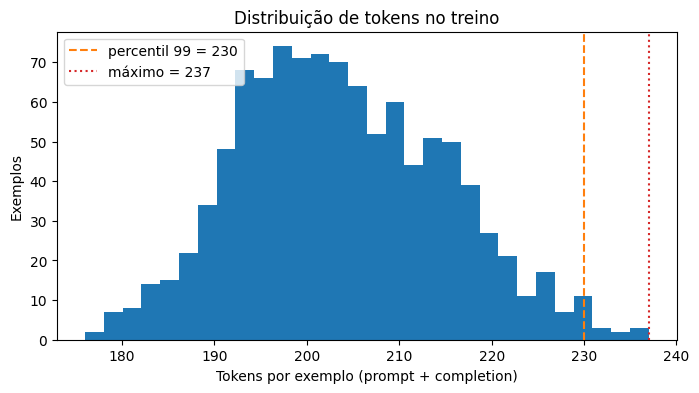

In [8]:
import matplotlib.pyplot as plt

treino = tokens.loc[tokens["split"] == "train", "total"]
p99 = treino.quantile(0.99)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(treino, bins=30, color="tab:blue")
ax.axvline(p99, color="tab:orange", linestyle="--", label=f"percentil 99 = {p99:.0f}")
ax.axvline(treino.max(), color="tab:red", linestyle=":", label=f"máximo = {treino.max()}")
ax.set_xlabel("Tokens por exemplo (prompt + completion)")
ax.set_ylabel("Exemplos")
ax.set_title("Distribuição de tokens no treino")
ax.legend()
plt.show()

### 3.5.2 Escolher o `max_length`

O `max_length` é o tamanho máximo da sequência no treino. Exemplos maiores são **truncados**, e o corte acontece no fim da sequência, que é justamente onde está a triagem. Um exemplo truncado ensina o modelo a gerar um JSON pela metade, sem o `<|im_end|>`.

A regra geral é cobrir cerca do percentil 99. Aqui a distribuição é estreita: o p99 e o máximo do treino estão próximos, e nenhum exemplo fica fora da curva. Então dá para cobrir **todos** os exemplos com folga e com custo de memória desprezível. Um exemplo muito maior que os outros indicaria um defeito de dado que escapou da Fase 2, como um alerta colado duas vezes.

**Decisão: `MAX_LENGTH = 256`**, a potência de 2 logo acima do maior exemplo. Ele cobre 100% dos três splits sem truncar nada:

In [9]:
MAX_LENGTH = 256

acima = tokens[tokens["total"] > MAX_LENGTH]
print(f"MAX_LENGTH = {MAX_LENGTH}")
print(f"Maior exemplo (todos os splits): {tokens['total'].max()} tokens")
print(f"Exemplos truncados: {len(acima)}")
assert acima.empty, "há exemplos maiores que MAX_LENGTH"
# Esperado: 0 exemplos truncados

MAX_LENGTH = 256
Maior exemplo (todos os splits): 237 tokens
Exemplos truncados: 0


## 3.6 Máscara de loss

O modelo deve ser penalizado apenas por errar a **triagem**, e não por "prever" o alerta, que ele recebe pronto. No formato prompt/completion, o `SFTTrainer` marca os tokens da completion ao tokenizar e monta uma coluna `labels` com `-100` em todos os outros tokens. No batch, o collator também coloca `-100` no padding. O `-100` diz ao PyTorch para ignorar aquele token no cálculo do loss.


### 3.6.1 Montar o `SFTTrainer` sem treinar

Montar o trainer só para que ele tokenize o treino do mesmo jeito que fará na Fase 5. Os hiperparâmetros de verdade são definidos na Fase 4:

In [10]:
import torch
from transformers import AutoModelForCausalLM
from trl import SFTConfig, SFTTrainer

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map="auto")

config_verificacao = SFTConfig(
    output_dir="outputs",
    max_length=MAX_LENGTH,
    per_device_train_batch_size=8,
    bf16=False,  # o SFTConfig liga bf16 por padrão, e a T4 não suporta bf16
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    args=config_verificacao,
    train_dataset=conversas["train"],
    processing_class=tokenizer,
)
print(trainer.train_dataset)
# Esperado: colunas input_ids e labels

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Tokenizing train dataset:   0%|          | 0/1033 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1033 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1033 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1033 [00:00<?, ? examples/s]

Dataset({
    features: ['prompt', 'completion', 'input_ids', 'labels'],
    num_rows: 1033
})


### 3.6.2 Decodificar os labels de um batch

Pegar um batch do trainer e decodificar a sequência inteira e depois só os tokens com `labels != -100`:

In [11]:
batch = next(iter(trainer.get_train_dataloader()))
input_ids, labels, atencao = batch["input_ids"][0], batch["labels"][0], batch["attention_mask"][0]
no_loss = labels != -100

print(f"Tokens da sequência: {int(atencao.sum())} | tokens no loss: {int(no_loss.sum())}")
print("\n--- Sequência completa ---")
print(tokenizer.decode(input_ids[atencao == 1]))
print("--- Somente os tokens no loss ---")
print(tokenizer.decode(input_ids[no_loss]))

Tokens da sequência: 199 | tokens no loss: 59

--- Sequência completa ---
<|im_start|>system
Você é um analista de SOC. Aplique a política de severidade da organização e responda apenas com o JSON da triagem.<|im_end|>
<|im_start|>user
EDR | Host: SRV-SQL-PRD-04 | Usuário: adm.i.monteiro | Processo: adfind.exe -f objectcategory=computer
Ativo: banco de dados de produção (criticidade: crítico) | Usuário: administrador, ferramenta não usada habitualmente pela equipe | Reputação: ferramenta legítima | Ocorrências em 7 dias: 1<|im_end|>
<|im_start|>assistant
{"veredito": "verdadeiro_positivo", "severidade": "alta", "justificativa": "Enumeração do Active Directory com ferramenta incomum para a equipe, em banco de dados de produção, ativo crítico."}<|im_end|>

--- Somente os tokens no loss ---
{"veredito": "verdadeiro_positivo", "severidade": "alta", "justificativa": "Enumeração do Active Directory com ferramenta incomum para a equipe, em banco de dados de produção, ativo crítico."}<|im_end|

O texto dos tokens no loss deve conter **somente** o JSON da triagem e o `<|im_end|>`, sem nada do prompt de sistema, do alerta ou do marcador `assistant`.

Conferir o mesmo para **todos** os exemplos do treino, e não só para um. Para cada sequência, os tokens no loss devem formar um JSON válido com as 3 chaves e terminar com o `<|im_end|>`:

In [12]:
CHAVES = {"veredito", "severidade", "justificativa"}
FIM_DE_TURNO = tokenizer.convert_tokens_to_ids("<|im_end|>")

verificados = 0
for batch in trainer.get_train_dataloader():
    for input_ids, labels in zip(batch["input_ids"], batch["labels"]):
        no_loss = input_ids[labels != -100]
        texto = tokenizer.decode(no_loss, skip_special_tokens=True)
        assert set(json.loads(texto)) == CHAVES, f"loss fora da triagem: {texto[:150]}"
        assert FIM_DE_TURNO in no_loss.tolist(), "<|im_end|> fora do loss"
        verificados += 1

print(f"Exemplos verificados: {verificados} de {len(conversas['train'])}")
# Esperado: todos os exemplos do treino

Exemplos verificados: 1033 de 1033


## 3.7 Publicar o dataset conversacional no Hub

Publicar os splits já no formato prompt/completion como dataset **público**. As Fases 4, 5 e 6 carregam este dataset direto, sem reescrever a conversão. Isso garante o mesmo `SYSTEM` e o mesmo formato em todas as fases, como pede a regra de ouro da seção 3.4.1:

In [13]:
SFT_ID = f"{conta['name']}/alertas-soc-sft"

conversas.push_to_hub(SFT_ID, private=False)

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpsif62olz.parquet    : 100%|##########|  686kB /  686kB            

... (12 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmprsryinev.parquet    : 100%|##########|  145kB /  145kB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/datasets/poliana-moraes/alertas-soc-sft/commit/2aa6327fbc0a93aca4d91aa7ba235a2ab4fe2497', commit_message='Upload dataset', commit_description='', oid='2aa6327fbc0a93aca4d91aa7ba235a2ab4fe2497', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/poliana-moraes/alertas-soc-sft', endpoint='https://huggingface.co', repo_type='dataset', repo_id='poliana-moraes/alertas-soc-sft'), pr_revision=None, pr_num=None)

Recarregar do Hub para confirmar a publicação. As fases seguintes carregam o dataset exatamente assim:

In [14]:
conversas = load_dataset(SFT_ID)
print(conversas)
print(conversas["train"][0]["prompt"][0]["content"])
# Esperado: o mesmo SYSTEM da seção 3.3

README.md:   0%|          | 0.00/662 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  686kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  152kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  145kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1033 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/224 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/221 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 1033
    })
    validation: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 224
    })
    test: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 221
    })
})
Você é um analista de SOC. Aplique a política de severidade da organização e responda apenas com o JSON da triagem.


## 3.8 Conclusão

Resultado da tokenização:

| Verificação | Resultado | Decisão |
|---|---|---|
| Chat template | Turnos com `<|im_start|>` / `<|im_end|>` e `SYSTEM` explícito | Mesmo `SYSTEM` no treino e na inferência |
| Tokens por exemplo (treino) | Mediana 203, p99 230, máximo 237. Prompt com cerca de 137 tokens e completion com cerca de 67 | `MAX_LENGTH = 256` |
| Exemplos fora da curva | Nenhum nos três splits (máximo geral de 237) | Nenhum exemplo truncado |
| Máscara de loss | Tokens no loss formam o JSON da triagem + `<|im_end|>` em 1.033 de 1.033 exemplos | Confirmada |

**Conclusão:** os 1.478 exemplos cabem em 256 tokens, e o JSON da triagem é cerca de um terço de cada sequência. A máscara de loss foi verificada exemplo a exemplo: o modelo só será penalizado pela triagem e pelo fim de turno, que é o que ensina a parar depois do JSON. O dataset no formato prompt/completion está publicado em `alertas-soc-sft`, e o `MAX_LENGTH` vai direto para a configuração do treino na Fase 4.